In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats, spatial

# Q3
"You learned earlier
in this chapter that stats.pearsonr does not support numpy
array matrix inputs, which means that getting p-values from
a correlation matrix requires a double for-loop over all pairs
of variables."

In [15]:
# matrix of p-values

N = 10000  # observations
M = 15  # features

# data matrix
X = np.random.randn(N, M)

# correlation matrix
R = np.corrcoef(X.T)

# confirm that it's the right shape
print(f'Correlation matrix shape: {R.shape}')

Correlation matrix shape: (15, 15)


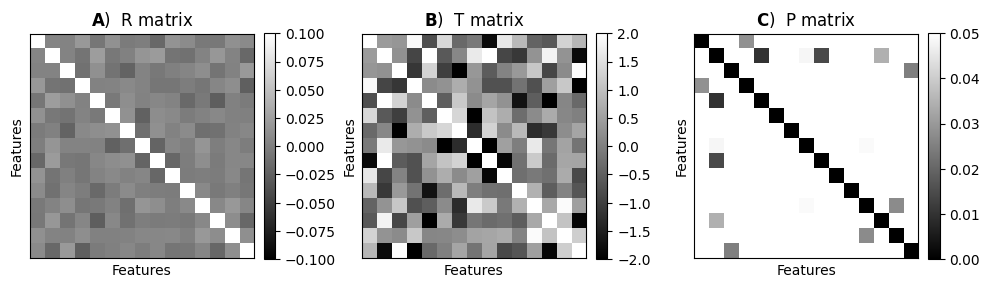

In [6]:
# compute the t-values
Tnum = R * np.sqrt(N - 2)
Tden = np.sqrt(1 - R ** 2) + np.finfo(float).eps  # adding a tiny number to avoid n/0

T = Tnum / Tden

# compute the p-values
P = stats.t.sf(T, N - 2)

# visualize all matrices
fig, axs = plt.subplots(1, 3, figsize=(10, 5))

cax = axs[0].imshow(R, vmin=-.1, vmax=.1, cmap='gray')
axs[0].set_title(r'$\bf{A}$)  R matrix')
c = fig.colorbar(cax, fraction=.046, pad=.04);
c.ax.tick_params(labelsize=10)

cax = axs[1].imshow(T, vmin=-2, vmax=2, cmap='gray')
axs[1].set_title(r'$\bf{B}$)  T matrix')
c = fig.colorbar(cax, fraction=.046, pad=.04);
c.ax.tick_params(labelsize=10)

cax = axs[2].imshow(P, vmin=0, vmax=.05, cmap='gray')
axs[2].set_title(r'$\bf{C}$)  P matrix')
c = fig.colorbar(cax, fraction=.046, pad=.04);
c.ax.tick_params(labelsize=10)

# properties common to all axes
for a in axs:
    a.set(xticks=[], yticks=[], xlabel='Features', ylabel='Features')
    a.spines[['right', 'top']].set_visible(True)

plt.tight_layout()
plt.show()

"It is interesting to note that because each column is created as
statistically independent random numbers, the p-values should
all be above .05. However, several H0 correlation coefficients
have p < .05. These are all Type-I errors. On the other
hand, there is no correction for multiple comparisons here,
so hopefully most or all of these coefficients would be non-
significant with a corrected α threshold."

# Q4

In [16]:
# create the sigma matrix
Sigma = np.std(X, ddof=1, axis=0)
Sigma = np.diag(Sigma)

# compute C from R
C_me = Sigma @ R @ Sigma  # from formula
C_np = np.cov(X.T, ddof=1)  # from numpy

# check for equality (these should all be True)
(C_np - C_me)

array([[ 1.11022302e-16,  1.38777878e-17,  1.38777878e-17,
         1.30104261e-18,  1.56125113e-17,  1.73472348e-18,
         6.07153217e-18, -2.16840434e-19, -7.80625564e-18,
        -2.60208521e-18, -3.46944695e-18, -1.73472348e-17,
        -1.04083409e-17,  1.38777878e-17,  4.33680869e-18],
       [ 1.56125113e-17,  3.55271368e-15, -2.77555756e-17,
        -3.90312782e-18,  1.25767452e-17, -1.56125113e-17,
        -8.67361738e-18,  1.04083409e-17,  1.73472348e-17,
         3.46944695e-17,  3.46944695e-18, -8.67361738e-19,
         2.60208521e-18,  1.38777878e-17, -2.08166817e-17],
       [ 1.21430643e-17, -2.94902991e-17,  2.66453526e-15,
         1.04083409e-17, -1.99493200e-17, -1.38777878e-17,
        -8.67361738e-19,  1.73472348e-17, -3.25260652e-18,
        -3.46944695e-17,  2.08166817e-17, -3.46944695e-18,
         3.46944695e-18, -1.73472348e-18,  7.58941521e-19],
       [ 1.30104261e-18, -3.46944695e-18,  8.67361738e-18,
        -1.11022302e-15,  4.77048956e-18,  1.38777878

In [17]:
# Now compute R from C
invSigma = 1 / np.std(X, ddof=1, axis=0)
invSigma = np.diag(Sigma)

R_me = invSigma @ C_np @ invSigma

# check for equality (these should all be True)
(R - R_me) < 1e-16

array([[ True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True],
       [ True,  True,  T

# Q5
"This and the next exercise will explore different ways of aver-
aging data when you have repeated measurements of the same
system. For example, in a brain imaging study, research par-
ticipants might look at pictures on a computer screen while
measuring their brain activity over time (each picture viewing
is a "repetition"). If you want to correlate activity in different
areas of the brain, you could either (1) average brain activity
over repetitions and then compute one correlation matrix, or
(2) compute the correlation matrix of each repetition and then
average the correlation matrices together. In other words, the
question is whether to average k data repetitions and then
compute one correlation matrix, or correlate each data repeti-
tion and then average the k correlation matrices."

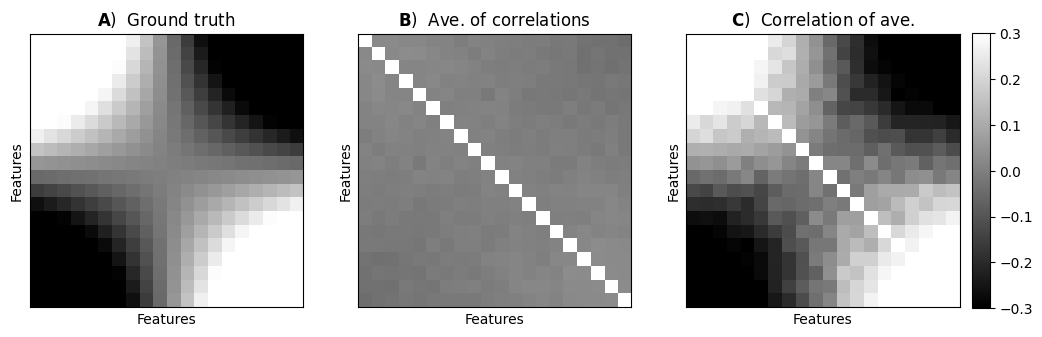

In [18]:
# simulation parameters
N = 1000  # observations
M = 20  # features

# number of repetitions
numReps = 30

# initialize data lists
alldata = np.zeros((M, N))
corrmats = np.zeros((M, M, numReps + 1))

# "pure" data
covars = np.linspace(-1, 1, M)[:, None]
dataOG = np.random.randn(N) * covars

# random noise in each repetition
for idx in range(numReps):
    # this run's data
    thisdata = dataOG + np.random.randn(M, N) * 5

    # its correlation matrix
    corrmats[:, :, idx] = np.corrcoef(thisdata)

    # sum the data
    alldata += thisdata

# correlation of data average
corrmats[:, :, -1] = np.corrcoef(alldata)

### plotting
fig, axs = plt.subplots(1, 3, figsize=(12, 5))

axs[0].imshow(covars @ covars.T, vmin=-.3, vmax=.3, cmap='gray')
axs[0].set_title(r'$\bf{A}$)  Ground truth')

axs[1].imshow(np.mean(corrmats[:, :, :-1], axis=2), vmin=-.3, vmax=.3, cmap='gray')
axs[1].set_title(r'$\bf{B}$)  Ave. of correlations')

cax = axs[2].imshow(corrmats[:, :, -1], vmin=-.3, vmax=.3, cmap='gray')
axs[2].set_title(r'$\bf{C}$)  Correlation of ave.')

cbar_ax = fig.add_axes([.91, .22, .015, .55])
cbar = plt.colorbar(cax, cax=cbar_ax)

# properties common to all axes
for a in axs:
    a.set(xticks=[], yticks=[], xlabel='Features', ylabel='Features')
    a.spines[['right', 'top']].set_visible(True)

# plt.tight_layout()
plt.show()

"data. It is quite clear that
the correlation of the average matches the ground truth better
than the average of the correlations. This suggests that it’s
better to average data first and then compute the correlation,
instead of averaging individual correlation matrices together.
But before you base your entire PhD analysis pipeline on this
one exercise, let’s see what happens in the next exercise..."

# Q6

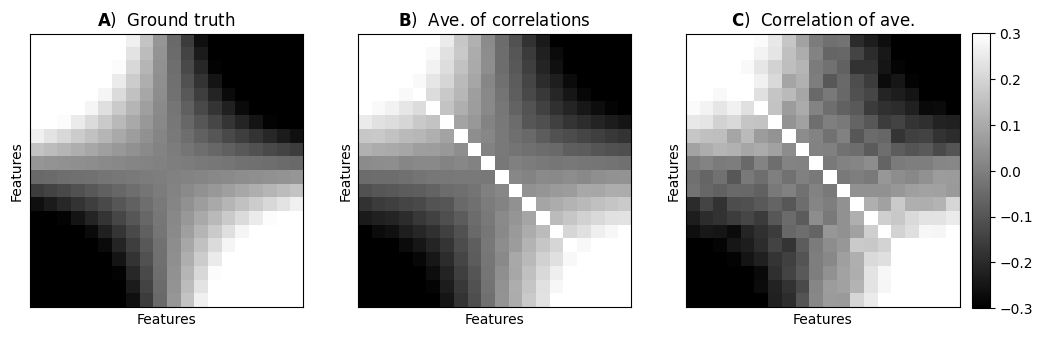

In [19]:
# re-initialize data lists
alldata = np.zeros((M, N))

### run the experiment
for idx in range(numReps):
    # this run's data (only 'covars' is constant across repetitions)
    thisdata = np.random.randn(N) * covars + np.random.randn(M, N)

    # its correlation matrix
    corrmats[:, :, idx] = np.corrcoef(thisdata)

    # store the data
    alldata += thisdata

# correlation of data average
corrmats[:, :, -1] = np.corrcoef(alldata)

### plotting
fig, axs = plt.subplots(1, 3, figsize=(12, 5))

axs[0].imshow(covars @ covars.T, vmin=-.3, vmax=.3, cmap='gray')
axs[0].set_title(r'$\bf{A}$)  Ground truth')

axs[1].imshow(np.mean(corrmats[:, :, :-1], axis=2), vmin=-.3, vmax=.3, cmap='gray')
axs[1].set_title(r'$\bf{B}$)  Ave. of correlations')

cax = axs[2].imshow(corrmats[:, :, -1], vmin=-.3, vmax=.3, cmap='gray')
axs[2].set_title(r'$\bf{C}$)  Correlation of ave.')

cbar_ax = fig.add_axes([.91, .22, .015, .55])
cbar = plt.colorbar(cax, cax=cbar_ax)

# properties common to all axes
for a in axs:
    a.set(xticks=[], yticks=[], xlabel='Features', ylabel='Features')
    a.spines[['right', 'top']].set_visible(True)

# plt.tight_layout()
plt.show()

"Why did this seemingly minor change have such a big impact?
In Exercise 5, the single-repetition noise was larger than the
meaningful variance in the data, so the single-repetition corre-
lation matrices were driven by noise; and because the noise was
randomly distributed around zero, averaging over the repeti-
tions meant averaging over the noise. But here in this exercise,
the data were repetition-unique, so the single-repetition corre-
lations were more meaningful while the data averaging reduced
the fidelity of the covariance.
This is a complicated set of simulations with a nuanced con-
clusion. These conclusions also depend on details of the sim-
ulation, noise characteristics, and magnitude of the data co-
variance. I don’t want you to draw specific conclusions about
when you would average data versus average correlation ma-
trices; the point is that selecting and averaging data involves
decisions that you need to make based on domain knowledge
about the topic area and the nature of the data."

# Q9
"Now for the direct comparison of cosine similarity vs. Pearson
correlation. "

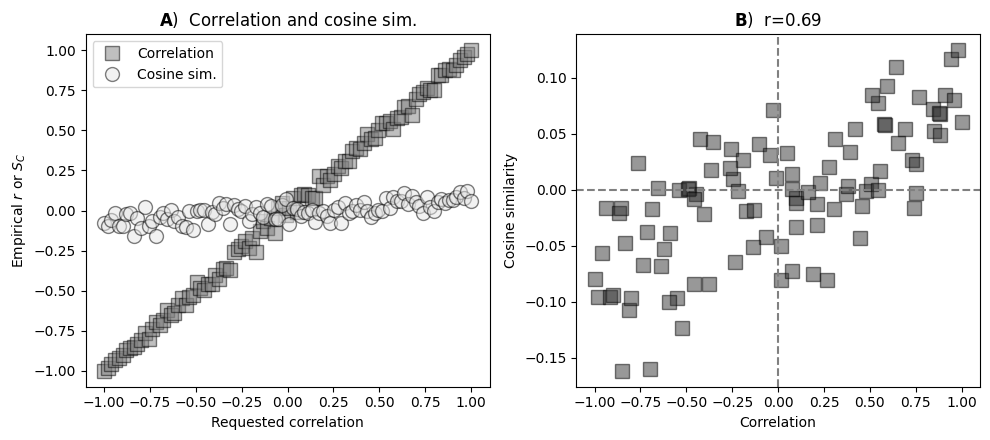

In [14]:
#  range of requested correlation coefficients
rs = np.linspace(-1, 1, 100)

# sample size
N = 500

# initialize output matrix
corrs = np.zeros((len(rs), 2))

# loop over a range of r values
for ri in range(len(rs)):
    # generate data
    x = np.random.randn(N)
    y = x * rs[ri] + np.random.randn(N) * np.sqrt(1 - rs[ri] ** 2)

    # mean de-centering
    x = x - 10

    # compute correlation
    corrs[ri, 0] = np.corrcoef(x, y)[0, 1]

    # compute cosine similarity
    corrs[ri, 1] = 1 - spatial.distance.cosine(x, y)

## visualize the results
_, axs = plt.subplots(1, 2, figsize=(10, 4.5))

axs[0].plot(rs, corrs[:, 0], 'ks', markersize=10, markerfacecolor=(.5, .5, .5), alpha=.5, label='Correlation')
axs[0].plot(rs, corrs[:, 1], 'ko', markersize=10, markerfacecolor=(.9, .9, .9), alpha=.5, label='Cosine sim.')
axs[0].legend()
axs[0].set(xlabel='Requested correlation', ylabel=r'Empirical $r$ or $S_C$')
axs[0].set_title(r'$\bf{A}$)  Correlation and cosine sim.')

axs[1].plot(corrs[:, 0], corrs[:, 1], 'ks', markersize=10, markerfacecolor=(.2, .2, .2), alpha=.5)
axs[1].axhline(y=0, color='gray', linestyle='--')
axs[1].axvline(x=0, color='gray', linestyle='--')
axs[1].set(xlabel='Correlation', ylabel='Cosine similarity')
axs[1].set_title(rf'$\bf{{B}}$)  r={np.corrcoef(corrs.T)[1, 0]:.2f}')

plt.tight_layout()
plt.show()

"Observations: The results in panel A are not surprising to me:
The mean offsets increase the denominator of the cosine simi-
larity equation, so naturally the coefficient will shrink. But I
do find the discordances between SC and r in panel B troubling
— for example, when the correlation coefficient is negative
while the cosine similarity is positive. I think the take-home
message here is to make sure that you are using the metric
that is appropriate for your data. On the other hand, you
can adjust the code to demonstrate that smaller mean offsets
produce tighter correspondences with fewer instances of con-
flicting signs."

# Q10

In [9]:
# import the data
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
column_names = ['MPG', 'Cylinders', 'Displacement', 'Horsepower', 'Weight', 'Acceleration', 'Model Year', 'Origin',
                'Car Name']

data = pd.read_csv(url, delim_whitespace=True, names=column_names, na_values="?")
data

/tmp/ipykernel_71352/3789952177.py:5: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(url,delim_whitespace=True,names=column_names, na_values="?")


,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Origin,Car Name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino
...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.0,2790.0,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52.0,2130.0,24.6,82,2,vw pickup
395,32.0,4,135.0,84.0,2295.0,11.6,82,1,dodge rampage
396,28.0,4,120.0,79.0,2625.0,18.6,82,1,ford ranger


In [11]:
data_numerical = data.drop(columns=['Car Name', 'Origin'])
R = data_numerical.corr(method='pearson')
R

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year
MPG,1.000000,-0.775396,-0.804203,-0.778427,-0.831741,0.420289,0.579267
Cylinders,-0.775396,1.000000,0.950721,0.842983,0.896017,-0.505419,-0.348746
Displacement,-0.804203,0.950721,1.000000,0.897257,0.932824,-0.543684,-0.370164
Horsepower,-0.778427,0.842983,0.897257,1.000000,0.864538,-0.689196,-0.416361
Weight,-0.831741,0.896017,0.932824,0.864538,1.000000,-0.417457,-0.306564
Acceleration,0.420289,-0.505419,-0.543684,-0.689196,-0.417457,1.000000,0.288137
Model Year,0.579267,-0.348746,-0.370164,-0.416361,-0.306564,0.288137,1.000000
